# import dataset

In [1]:
# from google.colab import files, drive

# up = files.upload()
# drive.mount('/content/drive')

In [1]:
import pandas as pd

df = pd.read_csv('AB_final.csv')
df.head(3)

,pen,vis,dsr-org
0,79.0,285,0.71
1,82.5,285,0.71
2,80.9,290,0.74


# define x , y

In [3]:
# x and y must be define as 2D

In [2]:
import numpy as np

x = np.array(df[['pen', 'vis']])   # 2D
y = np.array(df[['dsr-org']])      # 2D

x_pendsr = df[['pen']].values
y_pendsr = df[['dsr-org']].values

x_visdsr = df[['vis']].values
y_visdsr = df[['dsr-org']].values

# train test split

In [5]:
# # finding best random state 

# from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import StandardScaler
# sc_x = StandardScaler()
# sc_y = StandardScaler()
# from sklearn.svm import SVR
# svr = SVR()
# from sklearn.metrics import r2_score

# import time
# t1 = time.time()
# lst = []
# for i in range(1,1000):
#     x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=i)
#     x_train = sc_x.fit_transform(x_train)
#     x_test = sc_x.transform(x_test)
#     y_train = sc_y.fit_transform(y_train)
#     y_test = sc_y.transform(y_test)
#     y_train = np.ravel(y_train)
#     y_test = np.ravel(y_test)
#     svr.fit(x_train, y_train)
#     yhat_test = svr.predict(x_test)
#     r2 = r2_score(y_test, yhat_test)
#     lst.append(r2)

# t2 = time.time()
# print(f"run time: {round((t2 - t1) / 60 , 0)} min")
# print(f"r2_score: {round(max(lst), 2)}")
# rs = np.argmax(lst) + 1
# print(f"random_state: {rs}")

In [3]:
from sklearn.model_selection import train_test_split

rs = 328
ts = 0.2

# x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=ts, random_state=328)   # ts=0.2     rs=328
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=ts, random_state=rs)

x_train_pendsr, x_test_pendsr, y_train_pendsr, y_test_pendsr = train_test_split(x_pendsr, y_pendsr, test_size=ts, random_state=rs)
x_train_visdsr, x_test_visdsr, y_train_visdsr, y_test_visdsr = train_test_split(x_visdsr, y_visdsr, test_size=ts, random_state=rs)

# feature scaling

In [4]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

sc_x = StandardScaler().fit(x_train)
sc_y = StandardScaler().fit(y_train)

sc_x_pendsr = StandardScaler().fit(x_train_pendsr)
sc_y_pendsr = StandardScaler().fit(y_train_pendsr)

sc_x_visdsr = StandardScaler().fit(x_train_visdsr)
sc_y_visdsr = StandardScaler().fit(y_train_visdsr)

In [5]:
x_train = sc_x.transform(x_train)
x_test = sc_x.transform(x_test)

x_train_pendsr = sc_x_pendsr.transform(x_train_pendsr)
x_test_pendsr = sc_x_pendsr.transform(x_test_pendsr)
x_train_visdsr = sc_x_visdsr.transform(x_train_visdsr)
x_test_visdsr = sc_x_visdsr.transform(x_test_visdsr)

y_train = sc_y.transform(y_train)
y_test = sc_y.transform(y_test)

y_train_pendsr = sc_y_pendsr.transform(y_train_pendsr)
y_test_pendsr = sc_y_pendsr.transform(y_test_pendsr)
y_train_visdsr = sc_y_visdsr.transform(y_train_visdsr)
y_test_visdsr = sc_y_visdsr.transform(y_test_visdsr)

y_train = np.ravel(y_train)
y_test = np.ravel(y_test)

y_train_pendsr = np.ravel(y_train_pendsr)
y_test_pendsr = np.ravel(y_test_pendsr)
y_train_visdsr = np.ravel(y_train_visdsr)
y_test_visdsr = np.ravel(y_test_visdsr)

# fit train data

In [9]:
# # K-fold cross validation

# from sklearn.svm import SVR
# from sklearn.model_selection import GridSearchCV

# parameters = {
#     '': [],
#     '': []
# }

# sv = SVR()
# gs = GridSearchCV(estimator=sv, param_grid=parameters, cv=5)

# gs.fit(x_train, y_train)

# best_params = gs.best_params_
# print(best_params)

In [10]:
# def param
# kernel='rbf', degree=3, gamma='scale', coef0=0.0, tol=0.001, C=1.0
# epsilon=0.1, shrinking=True, cache_size=200, verbose=False, max_iter=-1

In [6]:
from sklearn.svm import SVR

svr = SVR()
svr.fit(x_train, y_train)

svr_pendsr = SVR()
svr_pendsr.fit(x_train_pendsr, y_train_pendsr)

svr_visdsr = SVR()
svr_visdsr.fit(x_train_visdsr, y_train_visdsr)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [12]:
# import matplotlib.pyplot as plt

# plt.scatter(x_train, y_train, color='b', s=15)
# xx = np.arange(np.min(x_train), np.max(x_train), 0.01).reshape(-1, 1)
# plt.plot(xx, svr.predict(xx), color='r')
# plt.show()

# predict test data

In [7]:
yhat_test = svr.predict(x_test)
yhat_test_pendsr = svr_pendsr.predict(x_test_pendsr)
yhat_test_visdsr = svr_visdsr.predict(x_test_visdsr)

# evaluating the model

In [8]:
from sklearn.metrics import r2_score

print("r2-score (train data): %0.4f" % r2_score(y_train, svr.predict(x_train)))
print("r2-score (test data): %0.4f" % r2_score(y_test, yhat_test))

print('------------------------')

print("r2-score (train_pendsr data): %0.4f" % r2_score(y_train_pendsr, svr_pendsr.predict(x_train_pendsr)))
print("r2-score (test_pendsr data): %0.4f" % r2_score(y_test_pendsr, yhat_test_pendsr))

print("r2-score (train_visdsr data): %0.4f" % r2_score(y_train_visdsr, svr_visdsr.predict(x_train_visdsr)))
print("r2-score (test_visdsr data): %0.4f" % r2_score(y_test_visdsr, yhat_test_visdsr))

r2-score (train data): 0.9149
r2-score (test data): 0.9495
------------------------
r2-score (train_pendsr data): 0.8211
r2-score (test_pendsr data): 0.8535
r2-score (train_visdsr data): 0.8438
r2-score (test_visdsr data): 0.8525


In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

print("=" * 60)
print("SVR MODEL - BOTH INPUTS (pen + vis)")
print("=" * 60)
print(f"MSE (train data): {mean_squared_error(y_train, svr.predict(x_train)):.4f}")
print(f"RMSE (train data): {np.sqrt(mean_squared_error(y_train, svr.predict(x_train))):.4f}")
print(f"MAE (train data): {mean_absolute_error(y_train, svr.predict(x_train)):.4f}")
print(f"R² (train data): {r2_score(y_train, svr.predict(x_train)):.4f}")

print(f"\nMSE (test data): {mean_squared_error(y_test, yhat_test):.4f}")
print(f"RMSE (test data): {np.sqrt(mean_squared_error(y_test, yhat_test)):.4f}")
print(f"MAE (test data): {mean_absolute_error(y_test, yhat_test):.4f}")
print(f"R² (test data): {r2_score(y_test, yhat_test):.4f}")

print('\n' + '-' * 60)
print("SVR MODEL - PEN ONLY")
print("-" * 60)
print(f"MSE (train_pendsr data): {mean_squared_error(y_train_pendsr, svr_pendsr.predict(x_train_pendsr)):.4f}")
print(f"RMSE (train_pendsr data): {np.sqrt(mean_squared_error(y_train_pendsr, svr_pendsr.predict(x_train_pendsr))):.4f}")
print(f"MAE (train_pendsr data): {mean_absolute_error(y_train_pendsr, svr_pendsr.predict(x_train_pendsr)):.4f}")
print(f"R² (train_pendsr data): {r2_score(y_train_pendsr, svr_pendsr.predict(x_train_pendsr)):.4f}")

print(f"\nMSE (test_pendsr data): {mean_squared_error(y_test_pendsr, yhat_test_pendsr):.4f}")
print(f"RMSE (test_pendsr data): {np.sqrt(mean_squared_error(y_test_pendsr, yhat_test_pendsr)):.4f}")
print(f"MAE (test_pendsr data): {mean_absolute_error(y_test_pendsr, yhat_test_pendsr):.4f}")
print(f"R² (test_pendsr data): {r2_score(y_test_pendsr, yhat_test_pendsr):.4f}")

print('\n' + '-' * 60)
print("SVR MODEL - VIS ONLY")
print("-" * 60)
print(f"MSE (train_visdsr data): {mean_squared_error(y_train_visdsr, svr_visdsr.predict(x_train_visdsr)):.4f}")
print(f"RMSE (train_visdsr data): {np.sqrt(mean_squared_error(y_train_visdsr, svr_visdsr.predict(x_train_visdsr))):.4f}")
print(f"MAE (train_visdsr data): {mean_absolute_error(y_train_visdsr, svr_visdsr.predict(x_train_visdsr)):.4f}")
print(f"R² (train_visdsr data): {r2_score(y_train_visdsr, svr_visdsr.predict(x_train_visdsr)):.4f}")

print(f"\nMSE (test_visdsr data): {mean_squared_error(y_test_visdsr, yhat_test_visdsr):.4f}")
print(f"RMSE (test_visdsr data): {np.sqrt(mean_squared_error(y_test_visdsr, yhat_test_visdsr)):.4f}")
print(f"MAE (test_visdsr data): {mean_absolute_error(y_test_visdsr, yhat_test_visdsr):.4f}")
print(f"R² (test_visdsr data): {r2_score(y_test_visdsr, yhat_test_visdsr):.4f}")
print("=" * 60)

SVR MODEL - BOTH INPUTS (pen + vis)
MSE (train data): 0.0851
RMSE (train data): 0.2918
MAE (train data): 0.1785
R² (train data): 0.9149

MSE (test data): 0.0561
RMSE (test data): 0.2368
MAE (test data): 0.1490
R² (test data): 0.9495

------------------------------------------------------------
SVR MODEL - PEN ONLY
------------------------------------------------------------
MSE (train_pendsr data): 0.1789
RMSE (train_pendsr data): 0.4230
MAE (train_pendsr data): 0.3048
R² (train_pendsr data): 0.8211

MSE (test_pendsr data): 0.1629
RMSE (test_pendsr data): 0.4036
MAE (test_pendsr data): 0.2875
R² (test_pendsr data): 0.8535

------------------------------------------------------------
SVR MODEL - VIS ONLY
------------------------------------------------------------
MSE (train_visdsr data): 0.1562
RMSE (train_visdsr data): 0.3952
MAE (train_visdsr data): 0.2946
R² (train_visdsr data): 0.8438

MSE (test_visdsr data): 0.1640
RMSE (test_visdsr data): 0.4049
MAE (test_visdsr data): 0.2987
R² 

# predict new data

In [10]:
print(sc_y.inverse_transform(svr.predict(sc_x.transform([[79, 285]])).reshape(-1, 1)))
print(sc_y_pendsr.inverse_transform(svr_pendsr.predict(sc_x_pendsr.transform([[79]])).reshape(-1, 1)))
print(sc_y_visdsr.inverse_transform(svr_visdsr.predict(sc_x_visdsr.transform([[285]])).reshape(-1, 1)))

[[0.77610051]]
[[0.85169733]]
[[0.75790687]]


# save the model

In [17]:
# import joblib

# joblib.dump(svr, 'svr_model.pkl')

# load the model

In [18]:
# import joblib

# svr = joblib.load('svr_model.pkl')

pen dsr

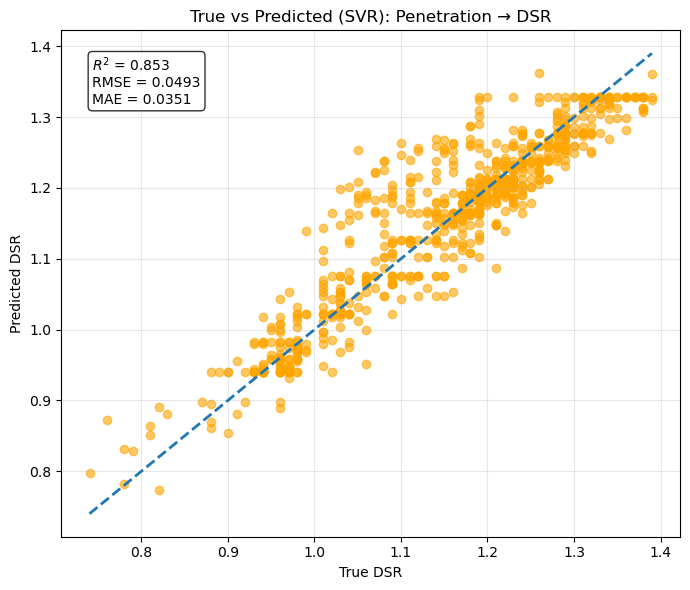

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Predict in standardized scale
y_pred_pen_scaled = svr_pendsr.predict(x_test_pendsr)

# Convert True and Predicted values back to original DSR scale
y_true_pen = sc_y_pendsr.inverse_transform(
    y_test_pendsr.reshape(-1, 1)
).ravel()

y_pred_pen = sc_y_pendsr.inverse_transform(
    y_pred_pen_scaled.reshape(-1, 1)
).ravel()

# Metrics in original DSR scale
r2_pen = r2_score(y_true_pen, y_pred_pen)
rmse_pen = np.sqrt(mean_squared_error(y_true_pen, y_pred_pen))
mae_pen = mean_absolute_error(y_true_pen, y_pred_pen)

# Plot
plt.figure(figsize=(7, 6))

plt.scatter(
    y_true_pen,
    y_pred_pen,
    color='orange',
    alpha=0.6
)

min_val = min(y_true_pen.min(), y_pred_pen.min())
max_val = max(y_true_pen.max(), y_pred_pen.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    '--',
    linewidth=2
)

plt.xlabel('True DSR')
plt.ylabel('Predicted DSR')
plt.title('True vs Predicted (SVR): Penetration → DSR')

plt.text(
    0.05, 0.95,
    f'$R^2$ = {r2_pen:.3f}\n'
    f'RMSE = {rmse_pen:.4f}\n'
    f'MAE = {mae_pen:.4f}',
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round',
        facecolor='white',
        alpha=0.8
    )
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('true_vs_pred_pen-dsr-svr.png', dpi=600)
plt.show()

vis dsr

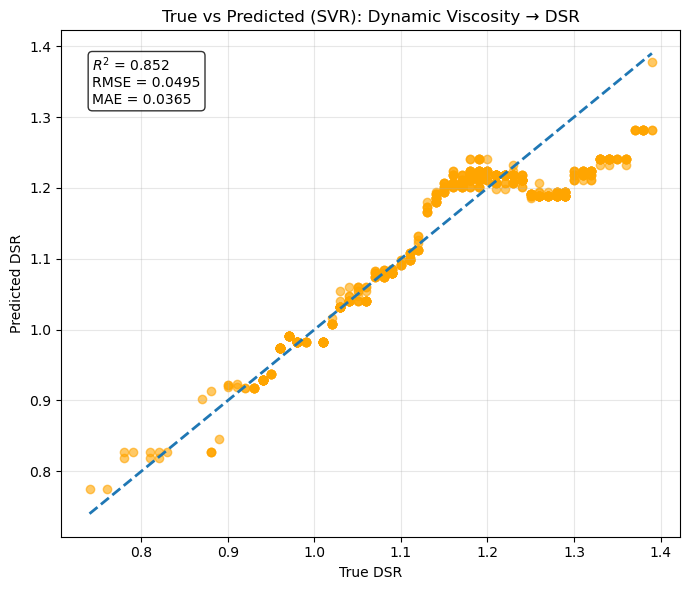

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Predict in standardized scale
y_pred_vis_scaled = svr_visdsr.predict(x_test_visdsr)

# Convert True and Predicted values back to original DSR scale
y_true_vis = sc_y_visdsr.inverse_transform(
    y_test_visdsr.reshape(-1, 1)
).ravel()

y_pred_vis = sc_y_visdsr.inverse_transform(
    y_pred_vis_scaled.reshape(-1, 1)
).ravel()

# Metrics in original DSR scale
r2_vis = r2_score(y_true_vis, y_pred_vis)
rmse_vis = np.sqrt(mean_squared_error(y_true_vis, y_pred_vis))
mae_vis = mean_absolute_error(y_true_vis, y_pred_vis)

# Plot
plt.figure(figsize=(7, 6))

plt.scatter(
    y_true_vis,
    y_pred_vis,
    color='orange',
    alpha=0.6
)

min_val = min(y_true_vis.min(), y_pred_vis.min())
max_val = max(y_true_vis.max(), y_pred_vis.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    '--',
    linewidth=2
)

plt.xlabel('True DSR')
plt.ylabel('Predicted DSR')
plt.title('True vs Predicted (SVR): Dynamic Viscosity → DSR')

plt.text(
    0.05, 0.95,
    f'$R^2$ = {r2_vis:.3f}\n'
    f'RMSE = {rmse_vis:.4f}\n'
    f'MAE = {mae_vis:.4f}',
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round',
        facecolor='white',
        alpha=0.8
    )
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('true_vs_pred_vis-dsr-svr.png', dpi=600)
plt.show()

pen,vis dsr

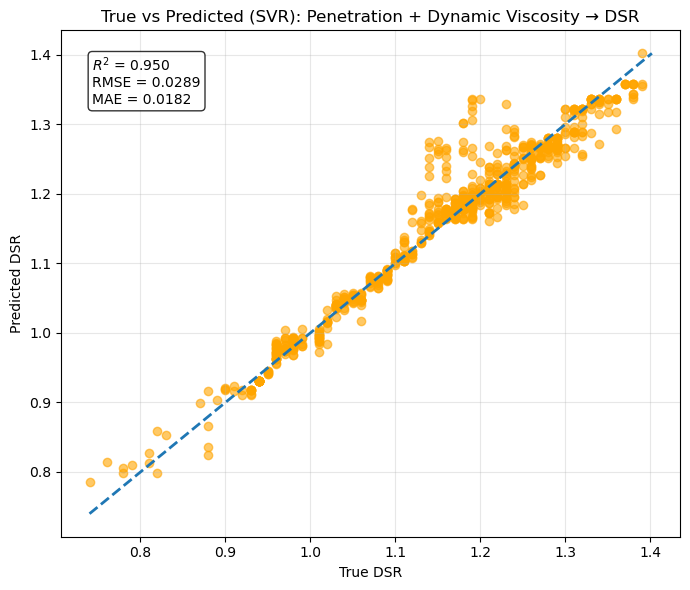

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Predict in standardized scale
y_pred_pen_vis_scaled = svr.predict(x_test)

# Convert True and Predicted values back to original DSR scale
y_true_pen_vis = sc_y.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

y_pred_pen_vis = sc_y.inverse_transform(
    y_pred_pen_vis_scaled.reshape(-1, 1)
).ravel()

# Metrics in original DSR scale
r2_pen_vis = r2_score(y_true_pen_vis, y_pred_pen_vis)
rmse_pen_vis = np.sqrt(mean_squared_error(y_true_pen_vis, y_pred_pen_vis))
mae_pen_vis = mean_absolute_error(y_true_pen_vis, y_pred_pen_vis)

# Plot
plt.figure(figsize=(7, 6))

plt.scatter(
    y_true_pen_vis,
    y_pred_pen_vis,
    color='orange',
    alpha=0.6
)

min_val = min(y_true_pen_vis.min(), y_pred_pen_vis.min())
max_val = max(y_true_pen_vis.max(), y_pred_pen_vis.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    '--',
    linewidth=2
)

plt.xlabel('True DSR')
plt.ylabel('Predicted DSR')
plt.title('True vs Predicted (SVR): Penetration + Dynamic Viscosity → DSR')

plt.text(
    0.05, 0.95,
    f'$R^2$ = {r2_pen_vis:.3f}\n'
    f'RMSE = {rmse_pen_vis:.4f}\n'
    f'MAE = {mae_pen_vis:.4f}',
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round',
        facecolor='white',
        alpha=0.8
    )
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('true_vs_pred_penvis-dsr-svr.png', dpi=600)
plt.show()